# Early stopping: which checkpoint?
Decision 15: train up to 5 epochs, save every 100 steps, pick the checkpoint with the lowest loss on the FULL validation set, measured with nll_ejemplo (not mlx's 25 batches). Test is looked at only once, with the chosen checkpoint.

We should see a point where the train loss still decreases but the validation stalls or even increases. That minimum should be our best model. Maybe at around pass 2, due to being a LoRA and having relatively little data.

In [1]:
import json, math
import mlx.core as mx
from mlx_lm import load

MODELO = "mlx-community/Qwen2.5-0.5B-Instruct-4bit"
PASOS = list(range(500, 6755, 500)) + [6700]  # one checkpoint every 500 steps, plus the last saved one

In [2]:
# Copied as is from Perplexity.ipynb
def nll_ejemplo(model, tokenizer, messages):
    full = tokenizer.apply_chat_template(messages)
    base_prompt = tokenizer.apply_chat_template(
        messages[:-1], add_generation_prompt=True)
    n_tokens = len(full) - len(base_prompt)
    logits = model(mx.array(full)[None])
    logits = logits[0, len(base_prompt)-1:len(full)-1]
    logits = logits.astype(mx.float32)
    logprobs = logits - mx.logsumexp(logits, axis=-1, keepdims=True)
    nll = 0
    for i in range(n_tokens):
        nll -= logprobs[i, full[len(base_prompt) + i]].item()
    mx.clear_cache()
    return (nll, n_tokens)

def medir(model, tokenizer, ruta):
    with open(ruta, "r") as f:
        ejemplos = [json.loads(line) for line in f if line.strip()]
    return [nll_ejemplo(model, tokenizer, e["messages"]) for e in ejemplos]

In [3]:
def resumen(resultados):
    nll = sum(r[0] for r in resultados)
    n = sum(r[1] for r in resultados)
    return nll / n

def curva(adaptador, ruta_valid):
    """Validation loss of every checkpoint in PASOS, loading each one's weights over the same model."""
    model, tokenizer = load(MODELO, adapter_path=adaptador)
    perdidas = {}
    for paso in PASOS:
        model.load_weights(f"{adaptador}/{paso:07d}_adapters.safetensors", strict=False)
        perdidas[paso] = resumen(medir(model, tokenizer, ruta_valid))
        print(f"step {paso:>4}: loss {perdidas[paso]:.3f}")
    return perdidas

In [7]:
import random

def muestra_train(ruta, n, semilla=0):
    """Same number of train examples as valid, chosen at random, written to a temp file so curva() can read it."""
    with open(ruta) as f:
        lineas = [l for l in f if l.strip()]
    elegidas = random.Random(semilla).sample(lineas, n)
    salida = ruta.replace("train.jsonl", "train_sample.jsonl")
    with open(salida, "w") as f:
        f.writelines(elegidas)
    return salida

TRAIN_RUN1 = muestra_train("../data/dataset/session/train.jsonl", 1012)
TRAIN_BM = muestra_train("../data/dataset/by_message/train.jsonl", 506)

## run1_5ep (split by sessions)

In [4]:
curva_run1 = curva("../adapters/run1_5ep", "../data/dataset/session/valid.jsonl")
mejor_run1 = min(curva_run1, key=curva_run1.get)
print("best:", mejor_run1, round(curva_run1[mejor_run1], 3))

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

step  500: valid loss 3.508
step 1000: valid loss 3.447
step 1500: valid loss 3.436
step 2000: valid loss 3.425
step 2500: valid loss 3.418
step 3000: valid loss 3.461
step 3500: valid loss 3.468
step 4000: valid loss 3.464
step 4500: valid loss 3.552
step 5000: valid loss 3.531
step 5500: valid loss 3.708
step 6000: valid loss 3.715
step 6500: valid loss 3.682
step 6700: valid loss 3.668
best: 2500 3.418


## by_message_5ep (split by messages, its validation also leaks)

In [5]:
curva_bm = curva("../adapters/by_message_5ep", "../data/dataset/by_message/valid.jsonl")
mejor_bm = min(curva_bm, key=curva_bm.get)
print("best:", mejor_bm, round(curva_bm[mejor_bm], 3))

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

step  500: valid loss 3.527
step 1000: valid loss 3.451
step 1500: valid loss 3.431
step 2000: valid loss 3.418
step 2500: valid loss 3.405
step 3000: valid loss 3.450
step 3500: valid loss 3.440
step 4000: valid loss 3.446
step 4500: valid loss 3.548
step 5000: valid loss 3.533
step 5500: valid loss 3.691
step 6000: valid loss 3.695
step 6500: valid loss 3.672
step 6700: valid loss 3.641
best: 2500 3.405


In [8]:
# Same measure (nll_ejemplo) on a random sample of train, same size as each validation set
train_run1 = curva("../adapters/run1_5ep", TRAIN_RUN1)
train_bm = curva("../adapters/by_message_5ep", TRAIN_BM)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

step  500: valid loss 3.358
step 1000: valid loss 3.218
step 1500: valid loss 3.118
step 2000: valid loss 3.029
step 2500: valid loss 2.938
step 3000: valid loss 2.840
step 3500: valid loss 2.757
step 4000: valid loss 2.685
step 4500: valid loss 2.577
step 5000: valid loss 2.490
step 5500: valid loss 2.376
step 6000: valid loss 2.288
step 6500: valid loss 2.206
step 6700: valid loss 2.176


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

step  500: valid loss 3.403
step 1000: valid loss 3.244
step 1500: valid loss 3.134
step 2000: valid loss 3.034
step 2500: valid loss 2.958
step 3000: valid loss 2.871
step 3500: valid loss 2.761
step 4000: valid loss 2.689
step 4500: valid loss 2.561
step 5000: valid loss 2.487
step 5500: valid loss 2.374
step 6000: valid loss 2.276
step 6500: valid loss 2.176
step 6700: valid loss 2.149


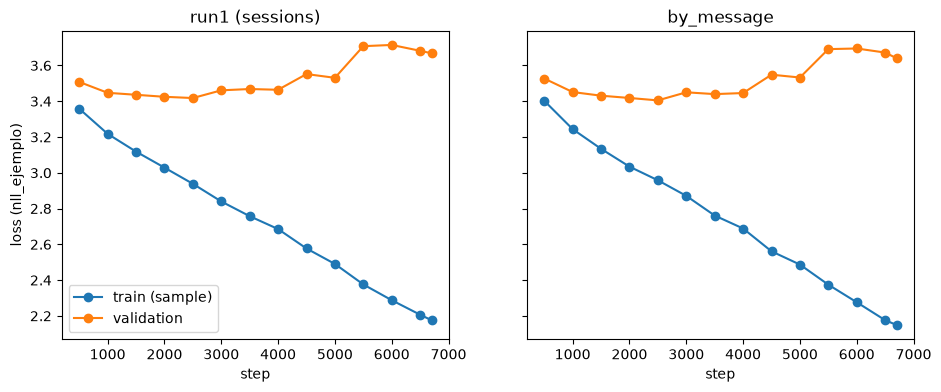

In [9]:
import matplotlib.pyplot as plt
fig, ejes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for eje, titulo, tr, va in [(ejes[0], "run1 (sessions)", train_run1, curva_run1), (ejes[1], "by_message", train_bm, curva_bm)]:
    eje.plot(list(tr), list(tr.values()), marker="o", label="train (sample)")
    eje.plot(list(va), list(va.values()), marker="o", label="validation")
    eje.set_title(titulo); eje.set_xlabel("step")
ejes[0].set_ylabel("loss (nll_ejemplo)"); ejes[0].legend(); plt.show()

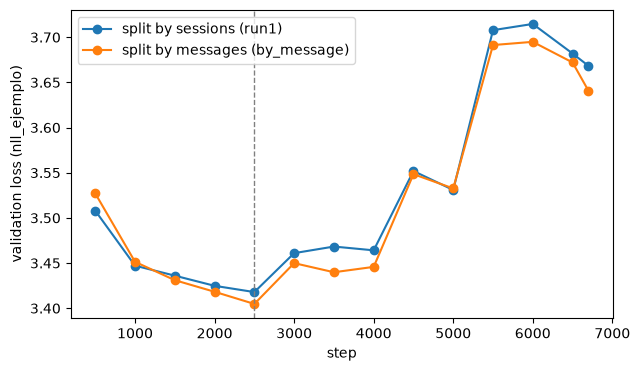

In [10]:
# Validation only, both splits on the same axes
import matplotlib.pyplot as plt
plt.figure(figsize=(7, 4))
plt.plot(list(curva_run1), list(curva_run1.values()), marker="o", label="split by sessions (run1)")
plt.plot(list(curva_bm), list(curva_bm.values()), marker="o", label="split by messages (by_message)")
plt.axvline(2500, color="gray", linestyle="--", linewidth=1)
plt.xlabel("step"); plt.ylabel("validation loss (nll_ejemplo)"); plt.legend(); plt.show()

### Conclusion

Taking all the steps into account, this is a clear case of overfitting. In both runs the train loss drops like a stone (sessions: 3.358 at step 500 to 2.176 at step 6,700; messages: 3.403 to 2.149), while the validation loss barely moves: it goes down from 3.51 to 3.42 until step 2,500 (about 1.85 epochs) and then climbs to 3.7. The best checkpoint is step 2,500 in both runs.

There is no significant difference between splitting by session and by message. The best validation loss is 3.418 with sessions and 3.405 with messages, a gap of 0.013, and the two curves have the same shape. The two validation sets are not the same examples (and the by_message one leaks), so what counts here is the shape, not the third decimal.

Training longer was not the answer. With this configuration the ceiling is around 3.42, so the limit is somewhere else: the learning rate, the capacity of the adapter, or the data.